# 05 — Heatmaps: do the explanations point at the mass, and do they explain the model?

**What this notebook does.** A heatmap is meant to show which parts of the image drove the model's
decision. This notebook makes heatmaps with three methods for every test patch and checks them in
four ways, using the radiologist's outline of each mass:

1. **Localisation:** does the heatmap land on the mass?
2. **Comparison with a model-free guess:** every patch is centred on its mass, so a blob in the middle
   of the image would land on the mass without knowing anything. A heatmap only shows something useful
   if it beats that blob.
3. **Weight-randomisation check** (Adebayo et al., 2018): scramble the model's weights and redraw the
   heatmap. If it barely changes, the heatmap is showing the image, not the model.
4. **Stability under degradation:** on degraded images (from notebook 04), does the heatmap move
   away from the mass?

**Methods**

| Method | How it works | Cost |
|---|---|---|
| Grad-CAM | Weights the last convolutional layer's feature maps by how much each one raises the score | One forward and backward pass |
| Grad-CAM++ | A refinement of Grad-CAM that weights positive gradients more carefully | Same as Grad-CAM |
| Occlusion | Covers each 32×32 square in turn with grey and measures how much the score drops | 169 forward passes per patch |

Each heatmap explains the class the model **predicted** (malignant or benign).

**Inputs** (Kaggle: *Add Input*): notebook 02 output (patches, outlines, `patch_index.csv`) and
notebook 03 output (`model/model.keras`, `model/locked.json`). Uses the **test** patches only.

**Settings.** Accelerator: GPU. Internet: not needed. Run with *Save Version → Save & Run All*.

**Outputs** (`/kaggle/working/heatmap_results`): tables, figures and `summary.json`.

## 0. Setup

In [1]:
import os, json, time, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import tensorflow as tf, keras

warnings.filterwarnings("ignore")
try: display
except NameError: display = print
SMOKE = os.environ.get("SMOKE") == "1"           # tiny test run only; ignore on Kaggle
CFG = dict(seed=42,
           n_random=20 if SMOKE else 100,        # patches used for the weight-randomisation check
           n_boot=100 if SMOKE else 1000,
           occ_patch=32, occ_stride=16)

def find(name):
    root = os.environ.get("INPUT_DIR", "/kaggle/input")
    hits = sorted(os.path.join(d, name) for d, _, f in os.walk(root, followlinks=True) if name in f)
    assert hits, f"{name} not found. Use 'Add Input' to attach the notebook that produced it."
    return hits[0]
INDEX = find("patch_index.csv"); PATCHES = os.path.dirname(INDEX)
LOCKED = find("locked.json"); MODEL_DIR = os.path.dirname(LOCKED)
OUT = os.environ.get("OUT_DIR", "/kaggle/working/heatmap_results"); os.makedirs(OUT, exist_ok=True)
np.random.seed(CFG["seed"]); tf.random.set_seed(CFG["seed"])
print("Patches from:", PATCHES, "| Model from:", MODEL_DIR, "| GPU:", tf.config.list_physical_devices("GPU"))

Patches from: /kaggle/input/notebooks/abdussalamhameedat/02-patch-notebook/patches | Model from: /kaggle/input/notebooks/abdussalamhameedat/03-training-and-calibration/model | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load the model and the test patches with their outlines
Patches are prepared exactly as in notebooks 03 and 04 (16-bit ÷ 257, resized to 224×224). The
outlines are resized the same way, so each outline lines up with what the model sees.

In [2]:
lock = json.load(open(LOCKED)); T, THR = lock["temperature"], lock["threshold"]
model = keras.models.load_model(os.path.join(MODEL_DIR, "model.keras"))
S = lock["config"]["img"]

idx = pd.read_csv(INDEX); d_te = idx[idx.split == "test"].reset_index(drop=True)
def native(rel):
    im = cv2.imread(os.path.join(PATCHES, rel), cv2.IMREAD_UNCHANGED)
    return np.round(im / 257.0).astype(np.uint8) if im.dtype == np.uint16 else im
to_input = lambda im: cv2.resize(im, (S, S), interpolation=cv2.INTER_AREA)
rgb = lambda X: np.repeat(X[..., None], 3, axis=-1).astype("float32")

N_te = [native(p) for p in d_te.img_path]
X = np.stack([to_input(im) for im in N_te])
M = np.stack([cv2.resize(cv2.imread(os.path.join(PATCHES, p), 0), (S, S), interpolation=cv2.INTER_NEAREST) > 127 for p in d_te.mask_path])
y = d_te.label.values.astype(int); g = d_te.patient_id.values
z = model.predict(rgb(X), batch_size=64, verbose=0).ravel(); p = 1 / (1 + np.exp(-z / T))
pred = (p >= THR).astype(int); correct = pred == y
print(f"{len(y)} test patches | mean outline area {M.mean():.1%} of the patch | "
      f"correct at the locked threshold: {correct.mean():.1%}")

378 test patches | mean outline area 24.7% of the patch | correct at the locked threshold: 54.8%


## 2. The three heatmap methods
All heatmaps are scaled to 0–1 and resized to 224×224. `out_relu` is MobileNetV2's last
convolutional layer (7×7 grid). For a patch predicted benign, the heatmap explains the benign
decision (the gradient of the negative score).

In [3]:
LAST = "out_relu"
def cams(mdl, Xs, bs=32):
    gm = keras.Model(mdl.input, [mdl.get_layer(LAST).output, mdl.output]); gc, gpp = [], []
    for k in range(0, len(Xs), bs):
        x = tf.constant(rgb(Xs[k:k + bs]))
        with tf.GradientTape() as tape:
            A, zz = gm(x, training=False)
            score = zz[:, 0] * tf.sign(zz[:, 0] + 1e-12)              # score for whichever class was predicted
        gr = tape.gradient(score, A)
        w = tf.reduce_mean(gr, axis=(1, 2), keepdims=True)              # Grad-CAM weights
        gc.append(tf.nn.relu(tf.reduce_sum(w * A, -1)).numpy())
        g2, g3 = gr ** 2, gr ** 3                                        # Grad-CAM++ weights
        den = 2 * g2 + tf.reduce_sum(A, axis=(1, 2), keepdims=True) * g3
        alpha = g2 / tf.where(tf.abs(den) > 1e-12, den, tf.ones_like(den))
        wpp = tf.reduce_sum(alpha * tf.nn.relu(gr), axis=(1, 2), keepdims=True)
        gpp.append(tf.nn.relu(tf.reduce_sum(wpp * A, -1)).numpy())
    up = lambda H: np.stack([cv2.resize(h / (h.max() + 1e-12), (S, S), interpolation=cv2.INTER_LINEAR) for h in np.concatenate(H)])
    return up(gc), up(gpp)

POS = [(r, c) for r in range(0, S - CFG["occ_patch"] + 1, CFG["occ_stride"]) for c in range(0, S - CFG["occ_patch"] + 1, CFG["occ_stride"])]
def occlusion(mdl, Xs):
    out, P = [], CFG["occ_patch"]
    for im in Xs:
        base = float(mdl.predict(rgb(im[None]), verbose=0).ravel()[0]); sign = 1.0 if base >= 0 else -1.0
        batch = np.repeat(im[None], len(POS), 0).copy()
        for n, (r, c) in enumerate(POS): batch[n, r:r + P, c:c + P] = im.mean()
        zz = mdl.predict(rgb(batch), batch_size=256, verbose=0).ravel()
        heat, cnt = np.zeros((S, S)), np.zeros((S, S))
        for (r, c), v in zip(POS, zz):
            heat[r:r + P, c:c + P] += sign * (base - v); cnt[r:r + P, c:c + P] += 1
        heat = np.maximum(heat / np.maximum(cnt, 1), 0); out.append(heat / (heat.max() + 1e-12))
    return np.stack(out)

t0 = time.time()
GC, GPP = cams(model, X); print(f"Grad-CAM and Grad-CAM++: {time.time() - t0:.0f}s")
t0 = time.time(); OCC = occlusion(model, X); print(f"Occlusion: {(time.time() - t0) / 60:.1f} min")
yy, xx = np.mgrid[0:S, 0:S]
BLOB = np.repeat(np.exp(-(((yy - S / 2) ** 2 + (xx - S / 2) ** 2) / (2 * (S / 4) ** 2)))[None], len(X), 0)
HEAT = {"Centre blob (no model)": BLOB, "Grad-CAM": GC, "Grad-CAM++": GPP, "Occlusion": OCC}

Grad-CAM and Grad-CAM++: 7s
Occlusion: 4.8 min


## 3. Localisation: does the heatmap land on the mass?

| Measure | Meaning |
|---|---|
| Pointing game | Share of patches where the **hottest point** of the heatmap is inside the outline |
| Heat inside outline | Share of the heatmap's total heat that falls inside the outline. For comparison, the outline covers on average the share of the patch given by `outline_area` |

95% intervals from bootstrapping by patient. The centre blob is the bar to beat.

In [4]:
def per_patch(H):
    hit = np.array([m[np.unravel_index(h.argmax(), h.shape)] for h, m in zip(H, M)], float)
    energy = np.array([h[m].sum() / (h.sum() + 1e-12) for h, m in zip(H, M)])
    return hit, energy
rng = np.random.default_rng(CFG["seed"]); pids = np.unique(g); rows_of = {q: np.where(g == q)[0] for q in pids}
BOOT = [np.concatenate([rows_of[q] for q in rng.choice(pids, len(pids))]) for _ in range(CFG["n_boot"])]
ci = lambda v: (float(v.mean()), float(np.quantile([v[s].mean() for s in BOOT], .025)), float(np.quantile([v[s].mean() for s in BOOT], .975)))
f3 = lambda t: f"{t[0]:.3f} ({t[1]:.3f}–{t[2]:.3f})"

PER = {}; rows = []
for name, H in HEAT.items():
    hit, energy = per_patch(H); PER[name] = (hit, energy)
    rows.append(dict(method=name, pointing_game=f3(ci(hit)), heat_inside_outline=f3(ci(energy))))
LOC = pd.DataFrame(rows); LOC["outline_area"] = f"{M.mean():.3f}"
LOC.to_csv(os.path.join(OUT, "table_localisation.csv"), index=False); display(LOC)

# Paired comparison with the centre blob (same bootstrap resamples)
def vs_blob(name, which):
    a, b = PER[name][which], PER["Centre blob (no model)"][which]; d = a - b
    return dict(method=name, measure=["pointing_game", "heat_inside_outline"][which],
                difference_vs_blob=round(float(d.mean()), 3),
                ci_low=round(float(np.quantile([d[s].mean() for s in BOOT], .025)), 3),
                ci_high=round(float(np.quantile([d[s].mean() for s in BOOT], .975)), 3))
VSB = pd.DataFrame([vs_blob(n, w) for n in ("Grad-CAM", "Grad-CAM++", "Occlusion") for w in (0, 1)])
VSB.to_csv(os.path.join(OUT, "table_vs_centre_blob.csv"), index=False); display(VSB)

,method,pointing_game,heat_inside_outline,outline_area
0,Centre blob (no model),0.976 (0.958–0.994),0.493 (0.485–0.502),0.247
1,Grad-CAM,0.574 (0.524–0.623),0.439 (0.416–0.463),0.247
2,Grad-CAM++,0.751 (0.706–0.793),0.501 (0.491–0.513),0.247
3,Occlusion,0.339 (0.288–0.391),0.194 (0.169–0.221),0.247


,method,measure,difference_vs_blob,ci_low,ci_high
0,Grad-CAM,pointing_game,-0.402,-0.453,-0.354
1,Grad-CAM,heat_inside_outline,-0.054,-0.077,-0.031
2,Grad-CAM++,pointing_game,-0.225,-0.271,-0.184
3,Grad-CAM++,heat_inside_outline,0.008,-0.000,0.015
4,Occlusion,pointing_game,-0.638,-0.691,-0.584
5,Occlusion,heat_inside_outline,-0.299,-0.324,-0.273


### Localisation by group
Heatmaps can behave differently for benign and malignant masses, and for correct and wrong
predictions. A method that points at the mass only when the model is right is less useful to a
reader trying to judge whether to trust a given prediction.

In [5]:
grp = []
for name in ("Grad-CAM", "Grad-CAM++", "Occlusion"):
    hit, energy = PER[name]
    for label, msk in (("benign", y == 0), ("malignant", y == 1), ("correct", correct), ("wrong", ~correct)):
        if msk.sum(): grp.append(dict(method=name, group=label, n=int(msk.sum()),
                                      pointing_game=round(float(hit[msk].mean()), 3), heat_inside_outline=round(float(energy[msk].mean()), 3)))
GRP = pd.DataFrame(grp); GRP.to_csv(os.path.join(OUT, "table_localisation_by_group.csv"), index=False)
display(GRP.pivot(index="group", columns="method", values="pointing_game").rename_axis("pointing game"))

method,Grad-CAM,Grad-CAM++,Occlusion
pointing game,,,
benign,0.519,0.706,0.225
correct,0.643,0.778,0.435
malignant,0.660,0.823,0.517
wrong,0.491,0.719,0.222


## 4. Weight-randomisation check
Following Adebayo et al. (2018), the model's weights are scrambled and the heatmaps redrawn:
- **Head scrambled:** only the final layer's weights are replaced with random values.
- **All layers scrambled:** every layer's weights are shuffled.

Similarity between the original and scrambled heatmaps is the Spearman rank correlation on a 14×14
grid (1 = same pattern, 0 = unrelated). A method that explains the model should give **low**
similarity. High similarity means the heatmap mostly reflects the image (edges, bright regions),
not what the model learned.

In [6]:
def scrambled(mdl, head_only):
    m2 = keras.models.clone_model(mdl); m2.set_weights(mdl.get_weights()); r = np.random.default_rng(CFG["seed"])
    for l in m2.layers:
        w = l.get_weights()
        if not w or (head_only and l.name != "head_logit"): continue
        if l.name == "head_logit": l.set_weights([r.normal(0, a.std() + 1e-3, a.shape).astype(a.dtype) for a in w])
        else: l.set_weights([r.permutation(a.ravel()).reshape(a.shape) for a in w])
    return m2
def similarity(H1, H2):
    small = lambda h: cv2.resize(h, (14, 14), interpolation=cv2.INTER_AREA).ravel()
    return np.array([spearmanr(small(a), small(b))[0] for a, b in zip(H1, H2)])

sub = np.sort(np.random.default_rng(CFG["seed"]).choice(len(X), min(CFG["n_random"], len(X)), replace=False))
rnd = []
for label, head_only in (("head scrambled", True), ("all layers scrambled", False)):
    m2 = scrambled(model, head_only)
    gc2, gpp2 = cams(m2, X[sub]); occ2 = occlusion(m2, X[sub])
    for name, a, b in (("Grad-CAM", GC[sub], gc2), ("Grad-CAM++", GPP[sub], gpp2), ("Occlusion", OCC[sub], occ2)):
        s = similarity(a, b); s = s[~np.isnan(s)]
        rnd.append(dict(method=name, scrambled=label, n=len(s), mean_similarity=round(float(s.mean()), 3) if len(s) else np.nan,
                        share_above_0_5=round(float((s > 0.5).mean()), 3) if len(s) else np.nan))
RND = pd.DataFrame(rnd); RND.to_csv(os.path.join(OUT, "table_randomisation.csv"), index=False)
display(RND.pivot(index="method", columns="scrambled", values="mean_similarity"))

scrambled,all layers scrambled,head scrambled
method,,
Grad-CAM,-0.311,0.334
Grad-CAM++,-0.571,0.983
Occlusion,-0.017,-0.029


## 5. Heatmaps on degraded images
The same degradations as notebook 04 (same code and seeds), Grad-CAM only. Two questions: does the
heatmap still land on the mass (pointing game), and how similar is it to the clean-image heatmap?

In [7]:
def jpeg(q): return lambda im, r: cv2.imdecode(cv2.imencode(".jpg", im, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_GRAYSCALE)
def lowres(f):
    def fn(im, r):
        h, w = im.shape; s_ = cv2.resize(im, (max(8, int(w * f)), max(8, int(h * f))), interpolation=cv2.INTER_AREA)
        return cv2.resize(s_, (w, h), interpolation=cv2.INTER_LINEAR)
    return fn
def noise(sd): return lambda im, r: np.clip(im + r.normal(0, sd, im.shape), 0, 255).astype(np.uint8)
def contrast(c): return lambda im, r: np.clip((im.astype(np.float32) - im.mean()) * c + im.mean(), 0, 255).astype(np.uint8)
def film_photo(k):
    def fn(im, r):
        h, w = im.shape
        out = cv2.GaussianBlur(im, (0, 0), 0.004 * k * max(h, w) + 0.5)
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        dst = (src + r.uniform(-1, 1, (4, 2)) * 0.03 * k * np.array([w, h])).astype(np.float32)
        out = cv2.warpPerspective(out, cv2.getPerspectiveTransform(src, dst), (w, h), borderMode=cv2.BORDER_REFLECT)
        a = r.uniform(0, 2 * np.pi); yy_, xx_ = np.mgrid[0:h, 0:w]
        grad = (np.cos(a) * (xx_ / w - .5) + np.sin(a) * (yy_ / h - .5)) * 0.35 * k
        out = np.clip(out.astype(np.float32) * (1 + grad), 0, 255).astype(np.uint8)
        return jpeg(70)(out, r)
    return fn
DEGR = {"jpeg_q20": jpeg(20), "jpeg_q10": jpeg(10), "res_quarter": lowres(0.25), "noise_sd15": noise(15),
        "contrast_x0.5": contrast(0.5), "film_photo_strong": film_photo(2)}
# Note: film_photo tilts the image slightly, so the outline no longer lines up exactly; its pointing game is approximate.

deg = [dict(condition="clean", pointing_game=round(float(PER["Grad-CAM"][0].mean()), 3), similarity_to_clean=1.0)]
for cond, fn in DEGR.items():
    Xd = np.stack([to_input(fn(im, np.random.default_rng(CFG["seed"] + i))) for i, im in enumerate(N_te)])
    gcd, _ = cams(model, Xd); hit, _ = per_patch(gcd); s = similarity(GC, gcd)
    deg.append(dict(condition=cond, pointing_game=round(float(hit.mean()), 3), similarity_to_clean=round(float(np.nanmean(s)), 3)))
DEG = pd.DataFrame(deg); DEG.to_csv(os.path.join(OUT, "table_heatmaps_degraded.csv"), index=False); display(DEG)

,condition,pointing_game,similarity_to_clean
0,clean,0.574,1.000
1,jpeg_q20,0.638,0.488
2,jpeg_q10,0.503,0.294
3,res_quarter,0.526,0.657
4,noise_sd15,0.725,0.512
5,contrast_x0.5,0.577,0.613
6,film_photo_strong,0.487,0.433


## 6. Example heatmaps
Eight test patches: correct and wrong predictions, benign and malignant. The green line is the
radiologist's outline. Failures are shown on purpose: a heatmap off the mass is a finding.

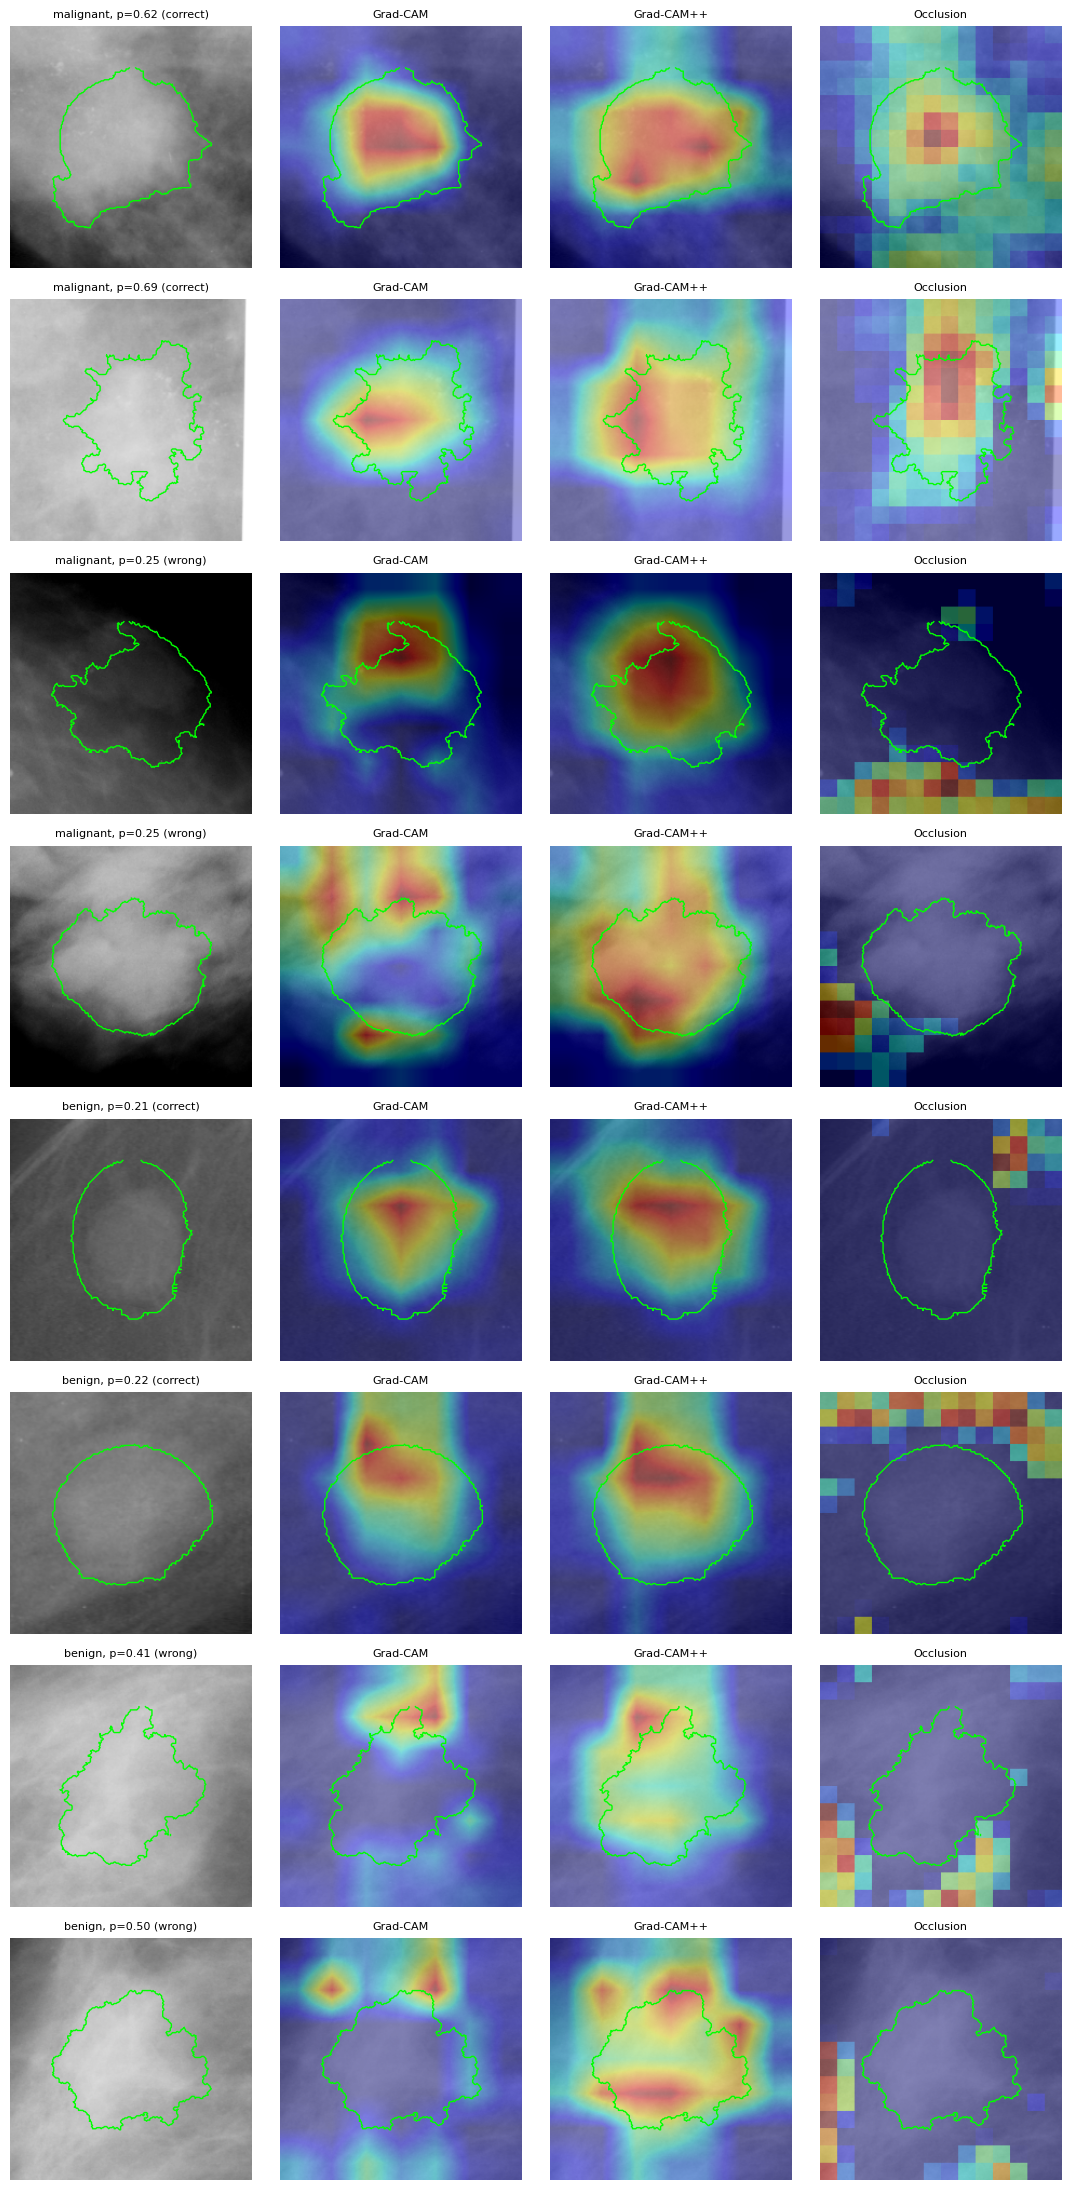

In [8]:
pick = []
for want_y in (1, 0):
    for want_c in (True, False):
        cand = np.where((y == want_y) & (correct == want_c))[0]
        pick += list(cand[:2])
fig, ax = plt.subplots(len(pick), 4, figsize=(11, 2.75 * len(pick)), squeeze=False)
for row, i in enumerate(pick):
    cnts, _ = cv2.findContours(M[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for col, (title, H) in enumerate((("", None), ("Grad-CAM", GC), ("Grad-CAM++", GPP), ("Occlusion", OCC))):
        a = ax[row, col]; a.imshow(X[i], cmap="gray", vmin=0, vmax=255)
        if H is not None: a.imshow(H[i], cmap="jet", alpha=0.4, vmin=0, vmax=1)
        for c in cnts: a.plot(c[:, 0, 0], c[:, 0, 1], c="lime", lw=1)
        a.set_title(title if col else f"{'malignant' if y[i] else 'benign'}, p={p[i]:.2f} "
                    f"({'correct' if correct[i] else 'wrong'})", fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_heatmap_examples.png"), dpi=130); plt.show()

## 7. Save a summary

In [9]:
summary = dict(test_patches=int(len(y)), mean_outline_area=float(M.mean()), share_correct=float(correct.mean()),
               localisation=LOC.to_dict("records"), vs_centre_blob=VSB.to_dict("records"),
               randomisation=RND.to_dict("records"), degraded=DEG.to_dict("records"), config=CFG)
json.dump(summary, open(os.path.join(OUT, "summary.json"), "w"), indent=2, default=str)
print("Files:", sorted(os.listdir(OUT)))

Files: ['fig_heatmap_examples.png', 'summary.json', 'table_heatmaps_degraded.csv', 'table_localisation.csv', 'table_localisation_by_group.csv', 'table_randomisation.csv', 'table_vs_centre_blob.csv']


## How to read the results
- **Beats the centre blob?** If a method's interval for "difference vs blob" sits above 0, its heatmaps
  find the mass better than a model-free guess. If not, its apparent localisation comes from the patches
  being centred on the mass.
- **Passes the randomisation check?** Low similarity after scrambling (well below 0.5) means the heatmap
  depends on what the model learned. High similarity means it mostly shows image structure.
- **Stable under degradation?** A falling pointing game and low similarity to the clean heatmap mean the
  explanation becomes unreliable in exactly the conditions this project targets.
- The outline is one radiologist's drawing and is approximate; spiculated malignant masses extend beyond
  it. A hottest point just outside the outline is not necessarily wrong.

**Reference:** Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). Sanity
checks for saliency maps. *Advances in Neural Information Processing Systems, 31*.